# Estudo de um KPI — treino, avaliação e explicabilidade, passo a passo

> **Notebook-irmão de [`scripts/evaluate_kpi.py`](../scripts/evaluate_kpi.py).** Cumpre o mesmo papel do
> script — do cockpit devolvido pelo ProModel ao metamodelo avaliado e explicado — chamando **as mesmas
> funções do pacote** (`sed_meta.study`), uma de cada vez, com a explicação de cada passo. Em resumo, ele:
>
> 1. lê o cockpit, separa as execuções completas e calcula o teto de ruído do KPI;
> 2. faz o split **agrupado por ponto** e ajusta o preprocessing só no treino;
> 3. compara as famílias de metamodelo: busca de hiperparâmetros com CV agrupada, CV na escala
>    original, hold-out e gatilhos de revisão da monografia;
> 4. escolhe o modelo de maior R² de **validação cruzada** e mede curva de aprendizado e sementes;
> 5. explica o escolhido com SHAP e PDP/ICE;
> 6. grava o estudo em `Código/runs/` e mostra a linha que iria para a aba eval.
>
> **Diferenças deliberadas:** este notebook grava em `Código/runs/notebook_eval_<id>/`, **nunca** registra
> na aba eval do `results-by-test.xlsx`, e — enquanto `FAKE = True` — avalia uma cópia do cockpit de
> entrada preenchida com **resultados falsos** (`sed_meta.fake_results`), só para exercitar o pipeline.
> Com os resultados do ProModel, troque para `FAKE = False`. O estudo oficial é feito pelo script:
>
> ```bash
> cd Código
> ../venv/Scripts/python.exe scripts/evaluate_kpi.py configs/scenario_01_serial.yaml --kpi Tempo_total
> ```

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RAIZ_CODIGO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ_CODIGO / "src"))

# Troque aqui: cenário, KPI (UM por estudo) e se os resultados são falsos
CENARIO = "scenario_01_serial"
KPI = "Tempo_total"
FAKE = True
MODELOS = ("dummy", "poly_ridge", "random_forest", "xgboost", "gp", "mlp")
N_ITER = 10          # combinações sorteadas por família (o script usa 20); o GP domina o tempo
SEED = 0
pd.set_option("display.max_columns", 30)

## 1. O cockpit devolvido: `load_results()`

O cockpit oficial volta do ProModel para
`promodel_interface/outputs_of_simulation/simulation_results_scenario_0N/`. `read_promodel_cockpit()` o lê
no vocabulário interno, `extract_results()` marca **cada** execução (completa / parcial / pendente /
inválida — nada some em silêncio) e `select_complete_runs()` fica só com as completas.

O **teto de ruído** do KPI (`compute_noise_ceiling`) é a fração da variância que é sinal; o resto é
ruído do simulador entre réplicas. É a régua de todas as métricas daqui para frente: nenhum metamodelo
pode ter R² legitimamente acima dele contra réplicas individuais. Se o modelo do ProModel for
determinístico (pendência (a) do context), as réplicas saem iguais e o teto vale 1.

In [2]:
from datetime import datetime
from sed_meta.campaign import interface_input_dir
from sed_meta.config import load_scenario_config
from sed_meta.fake_results import fill_with_fake_results
from sed_meta.study import latest_cockpit, load_results, results_dir

config = load_scenario_config(RAIZ_CODIGO / "configs" / f"{CENARIO}.yaml")
STUDY_ID = datetime.now().strftime("%y%m%d-%H%M")
OUT_DIR = RAIZ_CODIGO / "runs" / f"notebook_eval_{STUDY_ID}"

if FAKE:
    origem = latest_cockpit(interface_input_dir(config))
    COCKPIT = OUT_DIR / f"FAKE_{origem.name}"
    fill_with_fake_results(origem, COCKPIT, config, seed=SEED)
else:
    COCKPIT = latest_cockpit(results_dir(config))
print("cockpit:", COCKPIT.relative_to(RAIZ_CODIGO.parent))

leitura = load_results(COCKPIT, config, KPI)
print("status das execuções:", leitura["status"])
print(f"pontos completos: {leitura['completas']['point_id'].nunique()}  |  "
      f"teto de ruído de {KPI}: {leitura['noise_ceiling']:.3f}")
leitura["completas"][["point_id", "replication_id", *config.factor_names[:3], KPI]].head(6)

cockpit: Código\runs\notebook_eval_261103-0131\FAKE_cockpit_scenario_01_lhs_300x3_261103-0007.xlsx


status das execuções: {'completa': 900}
pontos completos: 300  |  teto de ruído de Tempo_total: 0.982


,point_id,replication_id,Capacidade M1,Quantidade chegada,Ocorrências chegada,Tempo_total
0,0,0,2,1,144,256.550
1,0,1,2,1,144,255.635
2,0,2,2,1,144,315.701
3,1,0,2,2,119,13.242
4,1,1,2,2,119,12.349
5,1,2,2,2,119,12.567


## 2. Split agrupado e preprocessing: `prepare()`

O treino é feito sobre as **réplicas** (não sobre médias): com K alvos diferentes para o mesmo X, o
modelo é empurrado para a resposta média sem decorar ruído. Por isso o split é **agrupado por
`point_id`** — um ponto inteiro, com todas as réplicas, vai para um lado só; `test_size` é a fração de
pontos. As entradas são escaladas pelos limites **declarados** do YAML; o KPI é padronizado com
estatísticas **só do treino** (`target_method="log_standard"` é a opção para tempos de fila
enviesados à direita).

In [3]:
from sed_meta.study import prepare

prep = prepare(leitura["completas"], config, KPI, target_method="standard", test_size=0.2, seed=SEED)
comuns = set(prep.train_df["point_id"]) & set(prep.test_df["point_id"])
print(f"treino: {prep.train_df['point_id'].nunique()} pontos ({len(prep.train_df)} linhas) | "
      f"teste: {prep.test_df['point_id'].nunique()} pontos ({len(prep.test_df)} linhas) | "
      f"pontos nos dois lados: {len(comuns)}")
print("X:", prep.X_train.shape, "| features:", prep.pipe.get_feature_names()[:4], "...")

treino: 240 pontos (720 linhas) | teste: 60 pontos (180 linhas) | pontos nos dois lados: 0
X: (720, 9) | features: ['Capacidade M1', 'Quantidade chegada', 'Ocorrências chegada', 'Frequência chegada'] ...


## 3. Comparação entre famílias: `compare_models()`

Para cada modelo do cardápio (`sed_meta.study.MODELOS`):

1. **busca de hiperparâmetros** na grade da família (`GRID_*` de `metamodels/`) com CV **agrupada**
   (`evaluation.tuning.tune_grouped`, um GridSearchCV com GroupKFold; com `n_iter`, sorteia
   combinações);
2. **CV agrupada** do melhor candidato, com métricas de treino e validação por fold na escala original;
3. **hold-out**: ajuste no treino inteiro e medida no teste, que não participou de nada antes;
4. **gatilhos** da monografia (`evaluation.diagnostics.diagnose`).

O dummy (sempre a média) é o piso; o polinomial regularizado responde se a superfície é simples —
se ele já resolve, isso é resultado sobre o sistema, não falta de modelo.

In [4]:
from sed_meta.study import compare_models

comparacao = compare_models(prep, MODELOS, noise_ceiling=leitura["noise_ceiling"],
                            n_splits=5, n_iter=N_ITER, seed=SEED)
tabela = comparacao["tabela"].sort_values("cv_validacao_r2", ascending=False)
tabela[["modelo", "familia", "cv_treino_r2", "cv_validacao_r2", "cv_validacao_r2_std",
        "teste_r2", "teste_rmse", "teste_mae", "fracao_do_teto", "fit_time_s", "gatilhos"]].round(3)

,modelo,familia,cv_treino_r2,cv_validacao_r2,cv_validacao_r2_std,teste_r2,teste_rmse,teste_mae,fracao_do_teto,fit_time_s,gatilhos
5,mlp,rede neural,0.983,0.975,0.003,0.977,21.797,12.381,0.996,0.337,erro_concentrado
4,gp,processo gaussiano,0.986,0.970,0.005,0.973,24.026,15.493,0.991,28.540,erro_concentrado
1,poly_ridge,baseline,0.985,0.969,0.007,0.971,24.708,16.154,0.989,0.005,erro_concentrado
3,xgboost,árvores,0.980,0.923,0.007,0.903,45.224,28.639,0.920,0.090,erro_concentrado
2,random_forest,árvores,0.985,0.883,0.015,0.871,52.077,30.388,0.888,0.815,"sobreajuste, erro_concentrado"
0,dummy,baseline,0.000,-0.014,0.015,-0.022,146.707,123.289,-0.022,0.000,subajuste


### 3.1 Escolha e gatilhos do escolhido

A escolha é pelo maior R² médio de **validação cruzada** — nunca pelo teste, que perderia a condição
de medida não enviesada. Os gatilhos dizem o que ajustar: no modelo (fluxo 3) ou no DoE (fluxo 2).

In [5]:
from sed_meta.evaluation.diagnostics import gatilhos_frame
from sed_meta.study import select_best

melhor = select_best(comparacao["tabela"])
det = comparacao["detalhes"][melhor]
print("escolhido:", melhor, det["tuning"]["params"])
print("teste:", {k: round(v, 4) for k, v in det["holdout"]["teste"].items()})
gatilhos_frame(det["gatilhos"])

escolhido: mlp {'hidden_layer_sizes': (64,), 'alpha': 1.0, 'activation': 'relu'}
teste: {'r2': 0.9774, 'rmse': 21.7975, 'mae': 12.3813, 'mse': 475.1302, 'rmse_mae': 1.7605, 'r2_t': 0.9774}


,codigo,observacao,interpretacao,ajuste_modelo,ajuste_doe,evidencia
0,erro_concentrado,MAE baixo combinado a RMSE alto,Erro concentrado em região específica do espaço,Revisar hiperparâmetros,Revisar estratégia amostral na região problemá...,RMSE/MAE no teste = 1.76 > 1.5


## 4. Volume de dados e estabilidade: `deepen()`

A curva de aprendizado treina o escolhido em frações **aninhadas** dos pontos de treino e mede sempre
no mesmo teste: se o erro de teste ainda cai na última fração, mais pontos de DoE ainda ajudam. O tempo
de treino mostra onde o custo da família cresce rápido. Para modelos com aleatoriedade no treino, a
estabilidade entre sementes completa a tabela de gatilhos.

,seed,fit_time_s,r2,rmse,mae,mse,rmse_mae,r2_t
0,0,0.325866,0.977154,21.935469,12.155459,481.164795,1.804578,0.977154
1,1,0.385910,0.977041,21.990031,12.313692,483.561470,1.785820,0.977041
2,2,0.413592,0.976343,22.321521,12.524697,498.250282,1.782200,0.976343
3,3,0.325845,0.977076,21.972808,12.083899,482.804286,1.818354,0.977076
4,4,0.164778,0.977045,21.988107,12.315111,483.476868,1.785458,0.977045


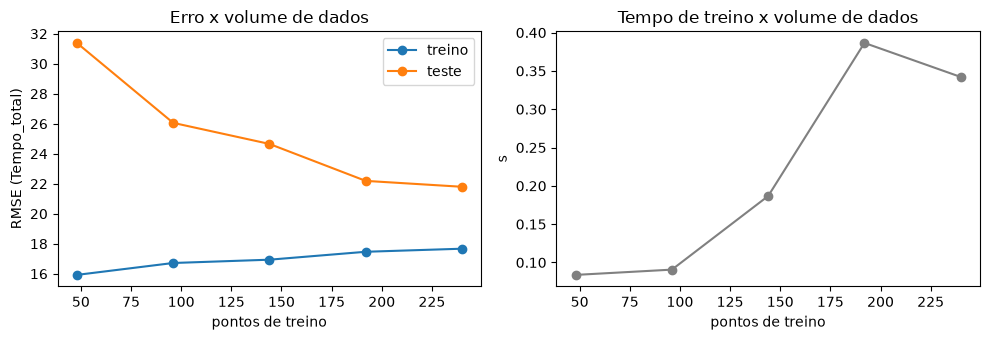

In [6]:
from sed_meta.study import deepen

aprofundamento = deepen(prep, det["tuning"]["estimador"], seed=SEED)
curva = aprofundamento["curva_aprendizado"]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(curva["n_pontos"], curva["treino_rmse"], "o-", label="treino")
ax1.plot(curva["n_pontos"], curva["teste_rmse"], "o-", label="teste")
ax1.set(xlabel="pontos de treino", ylabel=f"RMSE ({KPI})", title="Erro x volume de dados")
ax1.legend()
ax2.plot(curva["n_pontos"], curva["fit_time_s"], "o-", color="gray")
ax2.set(xlabel="pontos de treino", ylabel="s", title="Tempo de treino x volume de dados")
plt.tight_layout()
aprofundamento["sementes"]

## 5. Explicabilidade do escolhido: `explain()`

- **SHAP**: contribuição de cada parâmetro em cada previsão do teste. TreeSHAP (exato) para árvores,
  KernelSHAP (amostral) para os demais. A importância global é a média de |SHAP|, somada por parâmetro.
  Está na escala do modelo: o que se compara com a teoria na Fase 6 é a **ordem**.
- **PDP/ICE**: efeito médio de cada parâmetro (PDP) e uma curva por ponto (ICE), na escala original
  do parâmetro e do KPI. Curvas ICE não paralelas = interação que o PDP esconde.

,parametro,mean_abs_shap,fracao,rank
0,Quantidade chegada,0.803,0.471,1
1,Tempo processo 2,0.200,0.117,2
2,Ocorrências chegada,0.186,0.109,3
3,Capacidade M3,0.150,0.088,4
4,Tempo processo 3,0.142,0.083,5
5,Capacidade M1,0.114,0.067,6
6,Tempo processo 1,0.099,0.058,7
7,Frequência chegada,0.008,0.005,8
8,Capacidade M2,0.003,0.002,9


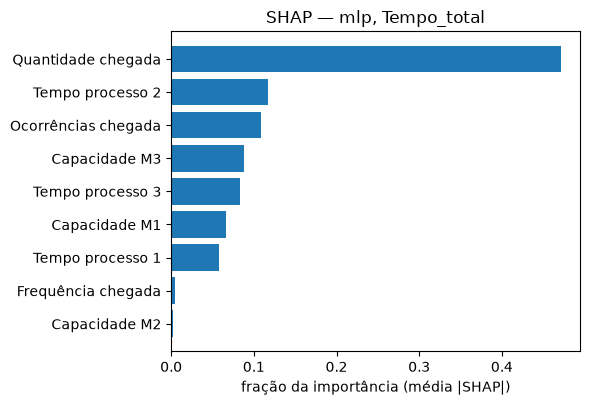

In [7]:
from sed_meta.study import explain

xai = explain(prep, det["holdout"]["modelo"], config, seed=SEED)
imp = xai["shap_importancia"]

fig, ax = plt.subplots(figsize=(6, 0.35 * len(imp) + 1))
ax.barh(imp["parametro"][::-1], imp["fracao"][::-1])
ax.set(xlabel="fração da importância (média |SHAP|)", title=f"SHAP — {melhor}, {KPI}")
plt.tight_layout()
imp.round(3)

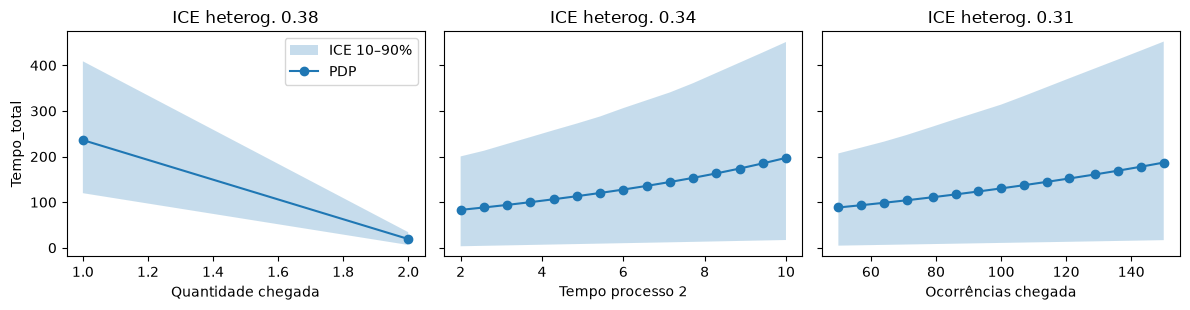

In [8]:
top = imp["parametro"].head(3).tolist()
fig, axes = plt.subplots(1, len(top), figsize=(4 * len(top), 3.2), sharey=True)
for ax, p in zip(np.atleast_1d(axes), top):
    d = xai["pdp"].loc[xai["pdp"]["parametro"] == p]
    ax.fill_between(d["valor"], d["p10"], d["p90"], alpha=0.25, label="ICE 10–90%")
    ax.plot(d["valor"], d["media"], "o-", label="PDP")
    ax.set(xlabel=p, title=f"ICE heterog. {xai['ice_heterogeneidade'][p]:.2f}")
np.atleast_1d(axes)[0].set_ylabel(KPI)
np.atleast_1d(axes)[0].legend()
plt.tight_layout()

## 6. Gravação e registro: `write_study()` / `eval_record_for()`

O estudo vai para `Código/runs/` (`resumo.json`, tabelas `.csv`, `modelo.joblib` e
`preprocessing.joblib`). A linha da aba `scenario N eval` é **só mostrada** aqui; quem grava é o script,
com `--register`, e só quando o usuário pede. Os textos de SHAP/PDP/ICE são ponto de partida — a
interpretação é do usuário.

In [10]:
from sed_meta.study import StudyResult, eval_record_for, summarize_study, write_study

resultado = StudyResult(STUDY_ID, KPI, COCKPIT, OUT_DIR, leitura, prep, comparacao, melhor,
                        aprofundamento, xai)
opcoes = {"modelos": list(MODELOS), "target_method": "standard", "test_size": 0.2, "n_splits": 5,
          "n_iter": N_ITER, "seed": SEED, "fake": FAKE}
resultado.resumo = summarize_study(resultado, config, opcoes)
write_study(resultado)
print("gravado em:", OUT_DIR.relative_to(RAIZ_CODIGO), sorted(p.name for p in OUT_DIR.iterdir()))
pd.Series(eval_record_for(resultado, config))

gravado em: runs\notebook_eval_261103-0131 ['FAKE_cockpit_scenario_01_lhs_300x3_261103-0007.xlsx', 'comparacao_modelos.csv', 'curva_aprendizado.csv', 'cv_por_fold.csv', 'ice_heterogeneidade.csv', 'modelo.joblib', 'pdp.csv', 'preprocessing.joblib', 'resumo.json', 'sementes.csv', 'shap_importancia.csv', 'shap_valores.csv', 'sobol.csv']


test_id                                                  261103-0131
kpi                                                      Tempo_total
doe_size                                                         300
n_replications                                                     3
surrogate_model                                                  mlp
model_params       hidden_layer_sizes=(64,), alpha=1.0, activatio...
promodel_time                                                   None
training_time                                               00:00:00
k_fold                                                             5
test_size                                                        0.2
r2                                                            0.9774
rmse                                                         21.7975
mse                                                         475.1302
mae                                                          12.3813
shap               ordem: Quantida

## Próximo passo

Com os resultados do ProModel em `outputs_of_simulation/`, rodar o script (sem `--fake`) para o KPI
escolhido, ler os gatilhos para decidir entre ajustar o modelo (fluxo 3) ou o DoE (fluxo 2), e levar a
ordem de importância do SHAP para a validação teórica (Fase 6).